In [1]:
import numpy as np
import math as mp
import pandas as pd

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
sigma = 5
beta = 1 /( 1.0 +0.01)
beta1 =1/( (1.0 +0.01* np.exp(30/(36.5*0.9)))) 
power = (1+2)/(-1-2)
W = 1
beta_hh =  beta


/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_77598/2773425506.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_77598/2773425506.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)


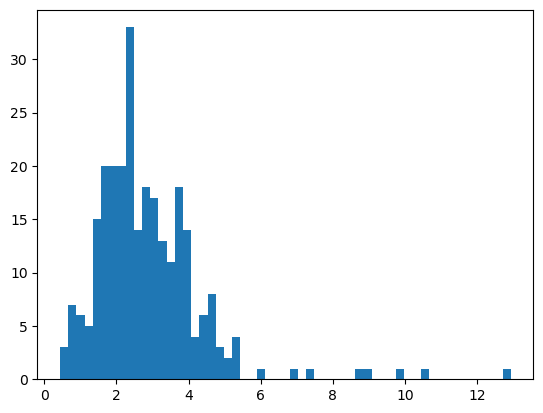

In [3]:
data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)
data_tau=(data['invtCogsRatio']* 36.5/(30*0.1))
import matplotlib.pyplot as plt
plt.hist(data_tau,bins = 55)
plt.show()

In [4]:
tau_diff = np.zeros(( 1000,1))
i = 0
for c in np.linspace(0, 0.99, 1000): 
    N = -(data_tau) - 1/np.log(beta*c) 
    tau1= -1/np.log(beta*c) - N
    tau1[tau1<0] = 0     
    tau2= -1/np.log(beta1*c) - N
    tau2[tau2<0] = 0    
    tau_diff[i] = np.mean(np.abs(tau1-tau2))
    i = i+1

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_77598/1678760125.py:4: RuntimeWarning: divide by zero encountered in log
  N = -(data_tau) - 1/np.log(beta*c)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_77598/1678760125.py:5: RuntimeWarning: divide by zero encountered in log
  tau1= -1/np.log(beta*c) - N
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_77598/1678760125.py:7: RuntimeWarning: divide by zero encountered in log
  tau2= -1/np.log(beta1*c) - N


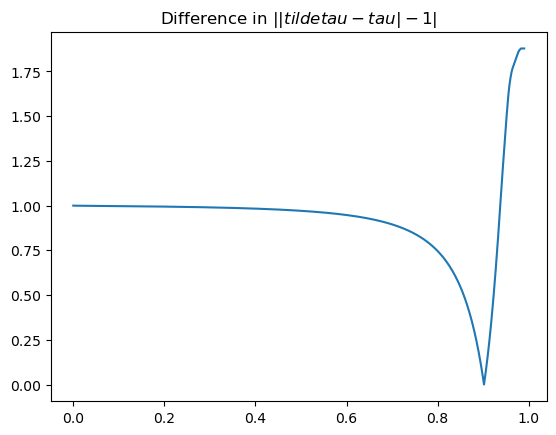

In [5]:
plt.plot(np.linspace(0, 0.99, 1000),np.abs(tau_diff-1))
plt.title('Difference in $||tildetau - tau| -1|$')

plt.show()

In [6]:
min_val = np.min(np.abs(tau_diff-1))
argmins = np.where(np.abs(tau_diff-1) == min_val)[0]

In [7]:
c_list = np.linspace(0, 0.99, 1000)
c= np.min(c_list[argmins])

In [8]:
N=-data_tau - 1/np.log(beta*c) 
tau= -1/np.log(beta*c) - N
tau[tau<0] = 0  
tau_floor = np.floor(tau)
tau_ceil = np.ceil(tau)
tprod_ceil=  (beta*c)**tau_ceil * (tau_ceil + N)
tprod_floor=  (beta*c)**tau_floor * (tau_floor + N)

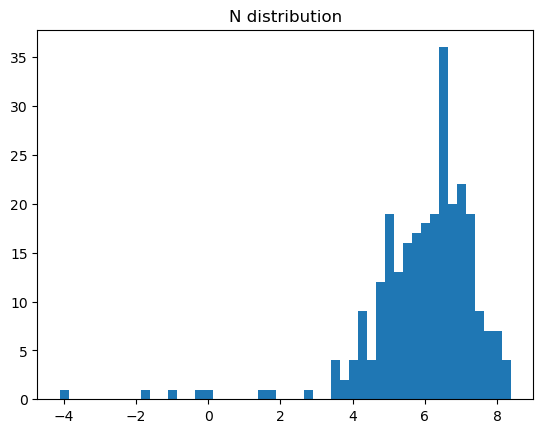

In [9]:
plt.hist(N, bins=50)
plt.title('N distribution')
plt.show()

In [10]:
tau[(tprod_ceil-tprod_floor)>0] = tau_ceil[(tprod_ceil-tprod_floor)>0]
tau[(tprod_ceil-tprod_floor)<0] = tau_floor[(tprod_ceil-tprod_floor)<0]
tau[tau<0] = 0  
tprod = (beta*c)**tau * (tau + N)

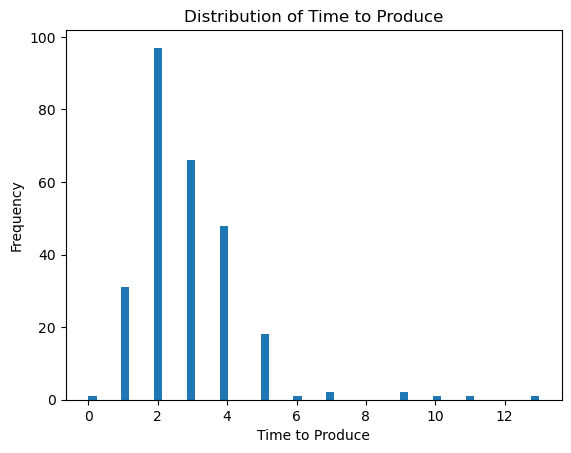

In [11]:
plt.hist(tau, bins = 55, alpha=1, label='tau_noise')
plt.xlabel('Time to Produce')
plt.ylabel('Frequency')
plt.title('Distribution of Time to Produce')
plt.show()

In [12]:

def generate_pattern_array_with_extra_rows(tau):
    # 1) Create the original n×n pattern
    n = len(tau)+ int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))

    mx = int(max(tau))
    missing_count = len(set(range(int(max(tau) )+ 1)) - set(tau))


    A = np.ones((m+2, n+missing_count), dtype=float)
    count = 0
    for i in range(1, m+2):
        for j in range(len(tau[tau == i-1])):
            A[i, n- i-j - count] = 0.997  # 0.9 shifts diagonally from right to left as we go down
        if len(tau[tau == i-1]) > 1:
            count += len(tau[tau == i-1])-1
    # 2) Create the two extra rows:
    #    (a) one row with 0.9 at the leftmost column,
    #    (b) one row of all ones.

    row_all_ones = np.ones(n+missing_count, dtype=float)
    A_extended = np.vstack([A,row_all_ones])
    A_extended = A_extended[:,0:n - int(np.min(tau))]

    return A_extended

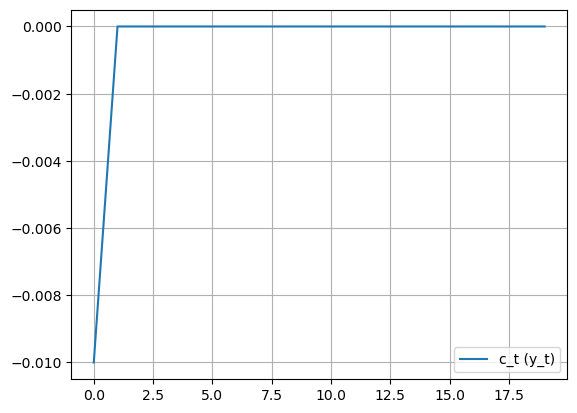

In [13]:
import numpy as np

def euler_path_fixed_wages(i_path, demand_level, theta):
    """
    Solve c_t = c_{t+1} - (1/sigma)*( i_t + Δabar_{t+1} )
    given nominal rate path i_t and log productivity path abar_t.
    Returns c_t (which equals y_t) and pi_t.
    """
    T = len(i_path)

    c = np.zeros(T+1)  # extra slot for terminal c_{T}
    # terminal condition: c_{T} = 0 deviation from steady state
    for t in range(T-1, -1, -1):
        if t+1 < T:
            c[t] = c[t+1] - (1.0/theta)*( i_path[t] - (1/beta_hh -1) +demand_level[t] )
        else:
           c[t] = c[t+1] - (1.0/theta)*( i_path[t] - (1/beta_hh -1) +demand_level[t])

    return c[:T]

# Example: fixed i=0, expected productivity sequence
T = 20
i_path = np.ones(T)*(1/(beta_hh)-1)  # fixed nominal rate
demand = np.zeros(T)
demand[0] = 0.01
c = euler_path_fixed_wages(i_path, demand, theta=1.0)

import matplotlib.pyplot as plt
plt.plot(c, label='c_t (y_t)')
plt.legend(); plt.grid(True); plt.show()

In [14]:
import numpy as np
import itertools

sequence_length = 3
r_choice = np.linspace(0, 0.02, 9)  # 6 values from 0 to 0.0125 inclusive

# Generate all possible combinations (Cartesian product)
all_combinations = list(itertools.product(r_choice, repeat=sequence_length))

# Convert to NumPy array
big_array = np.array(all_combinations)

print(big_array.shape)  # Should be (6^6, 6) = (46656, 6)

# Assign to r_arrange
r_arrange = big_array
size = r_arrange.shape[0]

(729, 3)


In [15]:
k=0
T = 10

deviation_gap = np.zeros((size, 1))
C_consumption = np.zeros((size, 10)) 
pi_inflation = np.zeros((size, 10))
for r in r_arrange: 
        

    # Example: fixed i=0, expected productivity sequence
    i_path = np.ones(T)*(1/(beta_hh)-1)   # fixed nominal rate
    demand = np.zeros(T)
    demand[0] = 0.01
    r_arrange_list = np.ones(T) *(1/(beta_hh)-1)
    r_arrange_list[0:sequence_length] = r_arrange[k]

    c = euler_path_fixed_wages(r_arrange_list, demand, theta=1.0)
    deviation_gap[k] = np.sum((c )**2)  
    C_consumption[k, :len(c)] = c.flatten()
    k = k+1

In [16]:
argmins_gap = np.where(deviation_gap == np.min(deviation_gap))[0]
argmins_gap

array([40])

In [17]:
target = np.array([0.01]*sequence_length)

matches = np.all(np.isclose(r_arrange, target), axis=1)

In [18]:
target2 = np.array([0, 0.01/3, 0.01/3])

matches2 = np.all(np.isclose(r_arrange, target2), axis=1)

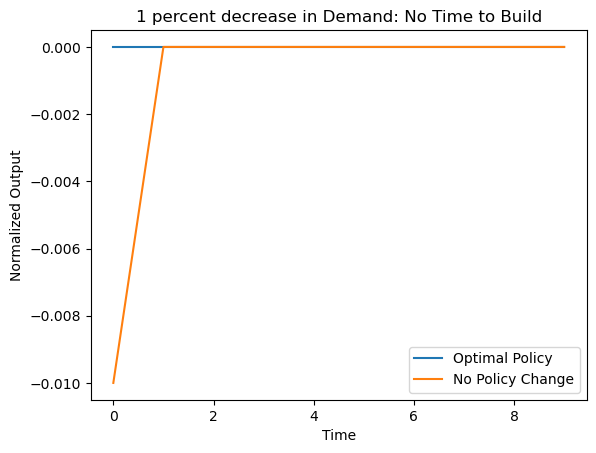

In [19]:
plt.plot( C_consumption[argmins_gap, :19].T, label='Optimal Policy')
plt.plot( C_consumption[matches, :19].T, label='No Policy Change')


plt.legend()
plt.title('1 percent decrease in Demand: No Time to Build')
plt.xlabel('Time')
plt.ylabel('Normalized Output') 
plt.show()

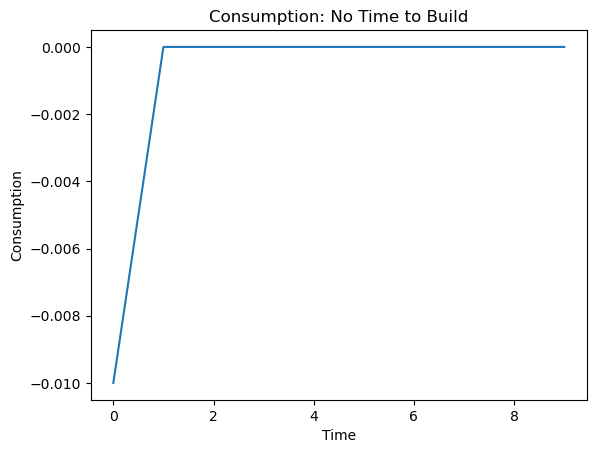

In [20]:
plt.plot(C_consumption[matches].T)
plt.xlabel('Time')
plt.ylabel('Consumption')
plt.title('Consumption: No Time to Build')
plt.show()

Best sequence index     : 40
Sum of squared deviation: 1.0532429383367696e-33
Interest-rate sequence  : [0.   0.01 0.01]


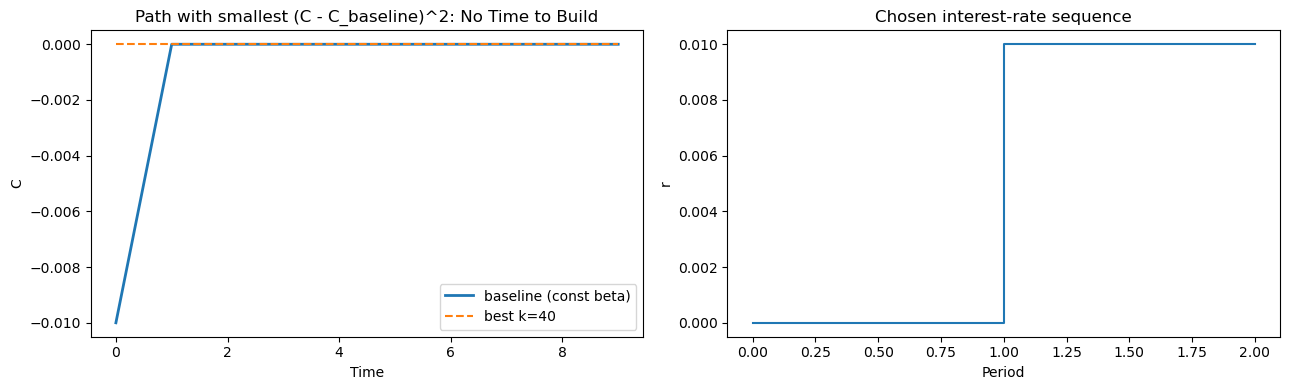

In [21]:
# --- best-policy / rate-path panel (same layout as hhhhhh.ipynb) ---
C_baseline = C_consumption[matches][0]          # no-policy-change (const beta) path
dev = np.asarray(deviation_gap).ravel()
best_k = int(np.argmin(dev))

print('Best sequence index     :', best_k)
print('Sum of squared deviation:', dev[best_k])
print('Interest-rate sequence  :', r_arrange[best_k])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(C_baseline, label='baseline (const beta)', linewidth=2)
axes[0].plot(C_consumption[best_k], '--', label=f'best k={best_k}')
axes[0].set_xlabel('Time'); axes[0].set_ylabel('C')
axes[0].set_title('Path with smallest (C - C_baseline)^2: No Time to Build')
axes[0].legend()

axes[1].step(np.arange(len(r_arrange[best_k])), r_arrange[best_k], where='post')
axes[1].set_xlabel('Period'); axes[1].set_ylabel('r')
axes[1].set_title('Chosen interest-rate sequence')
plt.tight_layout()
plt.show()

In [22]:
import numpy as np
import itertools

sequence_length = 3
r_choice = np.linspace(0, 0.0125, 6)  # 6 values from 0 to 0.0125 inclusive

# Generate all possible combinations (Cartesian product)
all_combinations = list(itertools.product(r_choice, repeat=sequence_length))

# Convert to NumPy array
big_array = np.array(all_combinations)

print(big_array.shape)  # Should be (6^6, 6) = (46656, 6)

# Assign to r_arrange
r_arrange = big_array
size = r_arrange.shape[0]

(216, 3)


In [23]:
import numpy as np

def euler_path_fixed_wages_2(i_path, price_level ,demand_level, theta):
    """
    Solve c_t = c_{t+1} - (1/sigma)*( i_t + Δabar_{t+1} )
    given nominal rate path i_t and log productivity path abar_t.
    Returns c_t (which equals y_t) and pi_t.
    """
    T = len(i_path)
    dA = np.zeros(T)
    dA[1:] = price_level[1:] - price_level[:-1]
    pi = dA  # price inflation
    c = np.zeros(T+1)  # extra slot for terminal c_{T}
    # terminal condition: c_{T} = 0 deviation from steady state
    for t in range(T-1, -1, -1):
        if t+1 < T:
            c[t] = c[t+1] - (1.0/theta)*( i_path[t]- dA[t+1] - (1/beta_hh -1) +demand_level[t] )
            
        else:
           c[t] = c[t+1] - (1.0/theta)*( i_path[t] - (1/beta_hh -1) )

    return c[:T]

In [24]:
k=0
T=30
deviation_gap = np.zeros((size, 1))
C_consumption = np.zeros((size, 30))
N_array = np.array(N)

# Compute tprod using product of first tau betas
tau_int = tau.astype(int)    
tvals = tau_int.to_numpy()
for r in r_arrange: 
        
    i_path = np.ones(T)*(1/(beta_hh)-1)   # fixed nominal rate
    abar = np.zeros(T)
    eps = np.zeros(T)

    interest_rate_list = np.ones((T,T)) * 0.01
    # Start with all rows = base

    n = len(r_arrange[k])
    r = np.asarray(r_arrange[k], dtype=float)
    fill = 0.01

    arr2d = np.full((n, n), fill, dtype=float)

    # Fill each row with the backward-looking rates
    for i in range(n):
        arr2d[i, :i+1] = r[i::-1]

    # Put into big matrix
    interest_rate_list[0:n, :n] = arr2d

    # Compute beta
    beta = 1.0 / (1.0 + interest_rate_list)

    cumprod_ext = np.ones((30,31))
    cumprod_ext[:,1:] = np.cumprod(beta,axis=1)
    beta_prod = cumprod_ext[:,tvals] 

    tprod_array = np.array((beta_prod * 0.9018018) * (((tvals + N_array))*np.ones((30,269)) ))
    prod_shock = np.ones((30,269))
    inside = 1/(tprod_array)**(sigma-1)
    A_prod = np.sum( inside,axis = 1)**(1/(sigma-1))

    i_path = np.ones(T)*(1/(beta_hh)-1)  # fixed nominal rate
    i_path[0:sequence_length] = r_arrange[k]  
    abar = np.log(A_prod)  # log productivity sequence

    demand = np.zeros(T)
    dA = np.zeros(T)
    dA[1:] = abar[1:] - abar[:-1]

    demand[0] = 0.01  # initial demand shock
    c = euler_path_fixed_wages_2(i_path, abar,demand, theta=1.0)
    deviation_gap[k] = np.sum((c )**2) + np.sum(dA**2)  
    C_consumption[k, :len(c)] = c.flatten() 
    k = k+1

In [25]:
target = np.array([0.01]*sequence_length)

matches = np.all(np.isclose(r_arrange, target), axis=1)

In [26]:
argmins_gap = np.where(deviation_gap == np.min(deviation_gap))[0]
argmins_gap

array([106])

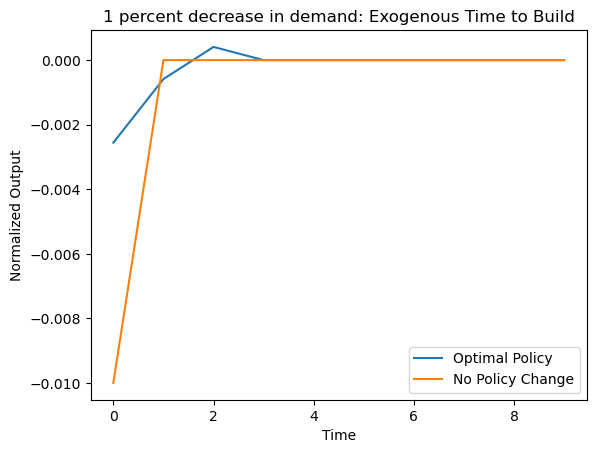

In [27]:
plt.plot( C_consumption[argmins_gap, :10].T, label='Optimal Policy')
plt.plot( C_consumption[matches, :10].T, label='No Policy Change' )


plt.legend()
plt.title('1 percent decrease in demand: Exogenous Time to Build')
plt.xlabel('Time')
plt.ylabel('Normalized Output') 
plt.show()

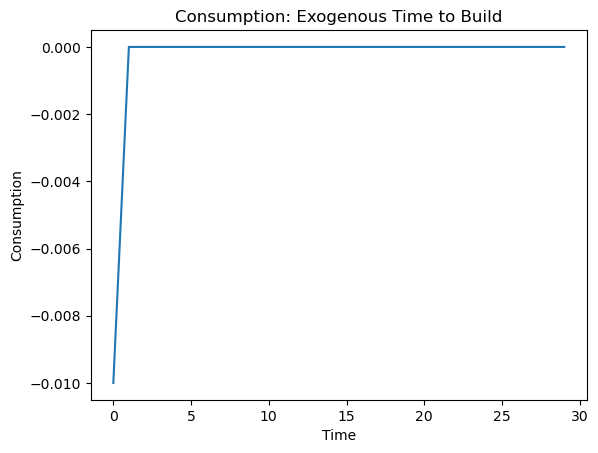

In [28]:
plt.plot(C_consumption[matches].T)
plt.xlabel('Time')
plt.ylabel('Consumption')
plt.title('Consumption: Exogenous Time to Build')
plt.show()

Best sequence index     : 106
Sum of squared deviation: 1.8658085710898055e-05
Interest-rate sequence  : [0.005  0.0125 0.01  ]


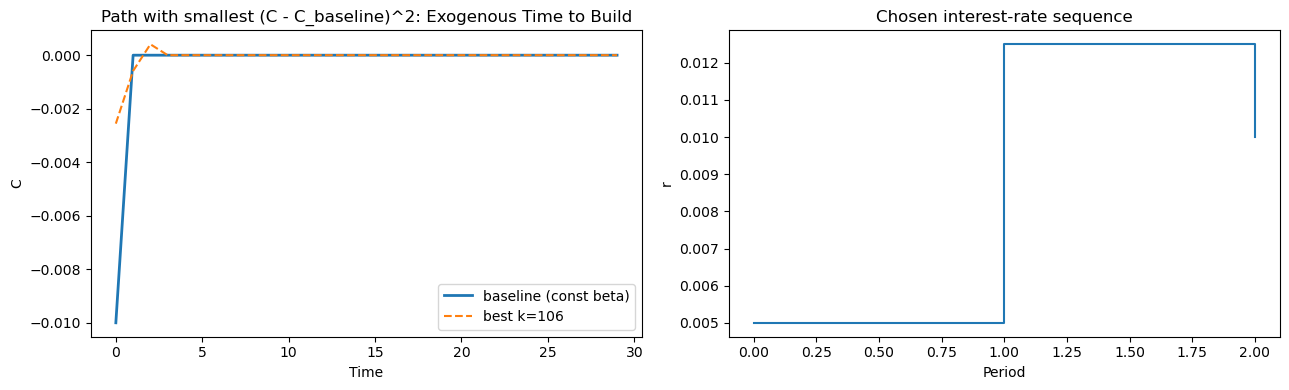

In [29]:
# --- best-policy / rate-path panel (same layout as hhhhhh.ipynb) ---
C_baseline = C_consumption[matches][0]          # no-policy-change (const beta) path
dev = np.asarray(deviation_gap).ravel()
best_k = int(np.argmin(dev))

print('Best sequence index     :', best_k)
print('Sum of squared deviation:', dev[best_k])
print('Interest-rate sequence  :', r_arrange[best_k])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(C_baseline, label='baseline (const beta)', linewidth=2)
axes[0].plot(C_consumption[best_k], '--', label=f'best k={best_k}')
axes[0].set_xlabel('Time'); axes[0].set_ylabel('C')
axes[0].set_title('Path with smallest (C - C_baseline)^2: Exogenous Time to Build')
axes[0].legend()

axes[1].step(np.arange(len(r_arrange[best_k])), r_arrange[best_k], where='post')
axes[1].set_xlabel('Period'); axes[1].set_ylabel('r')
axes[1].set_title('Chosen interest-rate sequence')
plt.tight_layout()
plt.show()